**Heart Failure Prediction**

In [31]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
import warnings
warnings.filterwarnings('ignore')

In [6]:
df = pd.read_csv('heart_failure_clinical_records.csv')

In [ ]:
df.head()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,55.0,0,748,0,45,0,263358.03,1.3,137,1,1,88,0
1,65.0,0,56,0,25,0,305000.00,5.0,130,1,0,207,0
2,45.0,0,582,1,38,0,319000.00,0.9,140,0,0,244,0
3,60.0,1,754,1,40,1,328000.00,1.2,126,1,0,90,0
4,95.0,1,582,0,30,0,461000.00,2.0,132,1,0,50,1


In [7]:
#if any null values
df.isna().sum()

,0
age,0
anaemia,0
creatinine_phosphokinase,0
diabetes,0
ejection_fraction,0
high_blood_pressure,0
platelets,0
serum_creatinine,0
serum_sodium,0
sex,0


In [8]:
#Dividing data into input and target features
X = df.drop(columns=['DEATH_EVENT'])
y = df['DEATH_EVENT']

In [9]:
X.head()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time
0,55.0,0,748,0,45,0,263358.03,1.3,137,1,1,88
1,65.0,0,56,0,25,0,305000.00,5.0,130,1,0,207
2,45.0,0,582,1,38,0,319000.00,0.9,140,0,0,244
3,60.0,1,754,1,40,1,328000.00,1.2,126,1,0,90
4,95.0,1,582,0,30,0,461000.00,2.0,132,1,0,50


In [10]:
#Data Normalization

from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
X[:] = scaler.fit_transform(X)


In [11]:
#Now all data scaled between 0 and 1
X.head()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time
0,0.272727,0,0.092498,0,0.469697,0,0.288833,0.089888,0.685714,1,1,0.298932
1,0.454545,0,0.004210,0,0.166667,0,0.339314,0.505618,0.485714,1,0,0.722420
2,0.090909,0,0.071319,1,0.363636,0,0.356286,0.044944,0.771429,0,0,0.854093
3,0.363636,1,0.093264,1,0.393939,1,0.367196,0.078652,0.371429,1,0,0.306050
4,1.000000,1,0.071319,0,0.242424,0,0.528428,0.168539,0.542857,1,0,0.163701


In [12]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [13]:
X_train.shape,X_test.shape

((4000, 12), (1000, 12))

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

In [15]:
def kfold(estimator, inp, tar):
  return cross_val_score(estimator,inp,tar,cv=5).mean() * 100

In [16]:
kfold(LogisticRegression(),X_train,y_train)

np.float64(85.25)

In [17]:
kfold(SVC(),X_train,y_train)

np.float64(89.525)

In [18]:
kfold(RandomForestClassifier(),X_train,y_train)

np.float64(99.15)

In [21]:
clf=GridSearchCV(RandomForestClassifier(),{
    'n_estimators':[50,100,150],
    'max_depth':[3,5,7],
    'min_samples_split':[2,3,4]
})
clf.fit(X_train,y_train)

GridSearchCV(estimator=RandomForestClassifier(),
             param_grid={'max_depth': [3, 5, 7], 'min_samples_split': [2, 3, 4],
                         'n_estimators': [50, 100, 150]})

In [22]:
clf_df= pd.DataFrame(clf.cv_results_)
clf_df.columns

Index(['mean_fit_time', 'std_fit_time', 'mean_score_time', 'std_score_time',
       'param_max_depth', 'param_min_samples_split', 'param_n_estimators',
       'params', 'split0_test_score', 'split1_test_score', 'split2_test_score',
       'split3_test_score', 'split4_test_score', 'mean_test_score',
       'std_test_score', 'rank_test_score'],
      dtype='object')

In [25]:
clf_df[[ 'param_max_depth', 'param_min_samples_split', 'param_n_estimators','mean_test_score']].sort_values(by='mean_test_score',ascending=False)

,param_max_depth,param_min_samples_split,param_n_estimators,mean_test_score
22,7,3,100,0.98025
20,7,2,150,0.98000
24,7,4,50,0.97975
25,7,4,100,0.97950
18,7,2,50,0.97875
23,7,3,150,0.97850
26,7,4,150,0.97825
21,7,3,50,0.97775
19,7,2,100,0.97725
15,5,4,50,0.94925


In [26]:
model=RandomForestClassifier(n_jobs=1,n_estimators=100,max_depth=7,min_samples_split=2)
model.fit(X_train,y_train)

RandomForestClassifier(max_depth=7, n_jobs=1)

In [27]:
y_test[:5]

,DEATH_EVENT
1501,0
2586,1
2653,1
1055,1
705,0


In [28]:
PRED=model.predict(X_test)
PRED[:5]

array([0, 1, 0, 1, 0])

In [29]:
accuracy_score= accuracy_score(y_test,PRED)
accuracy_score*100

97.8

In [30]:
print(classification_report(y_test,PRED))

              precision    recall  f1-score   support

           0       0.98      0.99      0.98       698
           1       0.98      0.95      0.96       302

    accuracy                           0.98      1000
   macro avg       0.98      0.97      0.97      1000
weighted avg       0.98      0.98      0.98      1000



Text(50.722222222222214, 0.5, 'Actual')

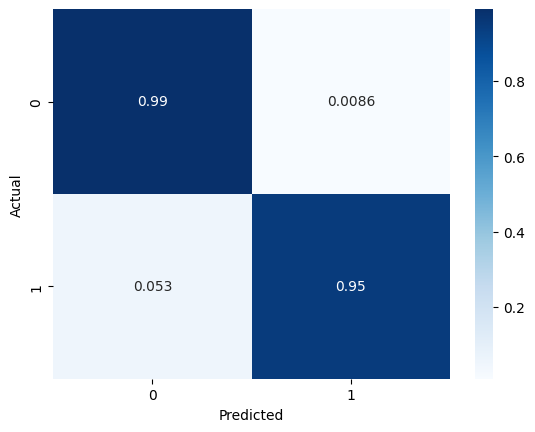

In [33]:
cf=confusion_matrix(y_test,PRED,normalize='true')
sns.heatmap(cf,annot=True,cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')